In [2]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
from scipy.signal import butter, filtfilt
from sklearn import metrics
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.naive_bayes import GaussianNB


In [3]:
WORKING_DIR=f"D:\FYP\Code\Dataset"
dataset_path = os.path.join(WORKING_DIR, "new_combined.csv")

Reading the dataset and preprocessing

In [4]:
# Check if the file exists
if os.path.exists(dataset_path):
    # Read the dataset
    df = pd.read_csv(dataset_path)
else:
    print(f"Error: File '{dataset_path}' not found.")

In [5]:
df = pd.read_csv(dataset_path)

In [6]:
df

,id,time,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,...,phase58_2,phase59_2,phase60_2,phase61_2,phase62_2,phase63_2,phase64_2,rssi_1,rssi_2,activity
0,368,10:16:40,118.726577,5.0,28.635642,30.805844,32.015621,32.893768,31.780497,30.886890,...,1.467715,1.532354,1.527345,1.515298,1.418147,1.212026,0.643501,-51,-48,4
1,369,10:16:40,118.726577,5.0,29.000000,31.144823,32.649655,32.202484,31.906112,30.413813,...,-2.944197,-2.922924,-2.886410,-2.934096,-2.999696,3.017238,2.356194,-51,-48,4
2,370,10:16:40,118.726577,5.0,29.154759,31.384710,32.449961,33.421550,32.557641,31.144823,...,-1.945130,-1.904041,-1.905533,-1.941688,-2.003204,-2.356194,-2.999696,-51,-48,4
3,371,10:16:40,118.726577,5.0,22.090722,24.020824,25.000000,25.079872,24.331050,23.537205,...,2.572279,2.594804,2.601173,2.582993,2.512796,2.191046,1.570796,-51,-48,4
4,372,10:16:40,118.726577,5.0,29.832868,31.780497,32.557641,33.136083,32.015621,31.064449,...,-2.910502,-2.889038,-2.853537,-2.875341,-2.966920,3.058451,2.622447,-51,-48,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235361,94215,19:24:02,115.277925,4.0,35.510562,37.735925,38.587563,38.078866,35.355339,30.886890,...,2.034444,-1.570796,-1.446441,-1.487655,-1.477320,-1.494024,-1.525373,-53,-53,0
235362,94216,19:24:02,115.277925,4.0,33.015148,33.837849,34.669872,34.132096,31.906112,27.459060,...,1.570796,-1.849096,-1.892547,-1.905533,-1.940130,-1.955954,-1.963854,-52,-53,0
235363,94217,19:24:02,115.277925,4.0,29.410882,30.675723,31.016125,30.463092,28.231188,25.079872,...,-1.249046,1.190290,1.227772,1.262744,1.238737,1.224257,1.212026,-52,-53,0
235364,94218,19:24:02,115.277925,4.0,34.014703,36.249138,37.161808,35.846897,33.615473,29.154759,...,-2.677945,0.785398,0.643501,0.610726,0.613207,0.588003,0.606988,-53,-54,0


In [7]:
#linear interpolation for a unified frequency
df_interpolated = df.interpolate(method='linear')

C:\Users\Lahiru Bandara\AppData\Local\Temp\ipykernel_16316\251419607.py:2: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_interpolated = df.interpolate(method='linear')


In [8]:
df_shuffled = df.sample(frac=1, random_state=42)  # frac=1 means shuffle all rows

In [9]:
df_shuffled.head()

,id,time,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,...,phase58_2,phase59_2,phase60_2,phase61_2,phase62_2,phase63_2,phase64_2,rssi_1,rssi_2,activity
21160,160,11:13:10,118.726577,5.0,24.698178,27.459060,29.681644,30.886890,30.463092,30.364453,...,-0.412410,-0.392340,-0.394791,-0.418224,-0.566729,-1.165905,-2.034444,-52,-49,0
77024,58,16:24:29,115.277925,4.0,38.639358,35.355339,30.265492,25.317978,20.615528,17.888544,...,0.211093,0.119429,-0.047583,-0.339293,-0.785398,-1.172274,-1.380808,-52,-53,1
33612,44,22:40:29,118.726577,5.0,22.022716,27.018512,29.206164,30.232433,30.528675,30.413813,...,0.735440,0.758378,0.753151,0.702257,0.540420,0.000000,-0.785398,-50,-49,5
140663,97,17:26:19,115.277925,4.0,43.382024,38.470768,33.615473,26.925824,20.591260,13.928388,...,-1.025141,-1.107149,-1.225241,-1.405648,-1.706324,-2.015216,-2.169215,-52,-53,1
121606,240,17:08:16,115.277925,4.0,43.104524,38.209946,32.140317,25.179357,17.029386,10.049876,...,2.207305,2.199593,2.158799,2.073640,1.923787,1.735945,1.518213,-52,-53,3


In [10]:
# Remove the first column (assuming it's the ID column)
df_shuffled = df_shuffled.drop(df_shuffled.columns[0], axis=1)

In [11]:
df_shuffled

,time,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,amplitude9_1,...,phase58_2,phase59_2,phase60_2,phase61_2,phase62_2,phase63_2,phase64_2,rssi_1,rssi_2,activity
21160,11:13:10,118.726577,5.0,24.698178,27.459060,29.681644,30.886890,30.463092,30.364453,28.442925,...,-0.412410,-0.392340,-0.394791,-0.418224,-0.566729,-1.165905,-2.034444,-52,-49,0
77024,16:24:29,115.277925,4.0,38.639358,35.355339,30.265492,25.317978,20.615528,17.888544,17.029386,...,0.211093,0.119429,-0.047583,-0.339293,-0.785398,-1.172274,-1.380808,-52,-53,1
33612,22:40:29,118.726577,5.0,22.022716,27.018512,29.206164,30.232433,30.528675,30.413813,28.231188,...,0.735440,0.758378,0.753151,0.702257,0.540420,0.000000,-0.785398,-50,-49,5
140663,17:26:19,115.277925,4.0,43.382024,38.470768,33.615473,26.925824,20.591260,13.928388,9.055385,...,-1.025141,-1.107149,-1.225241,-1.405648,-1.706324,-2.015216,-2.169215,-52,-53,1
121606,17:08:16,115.277925,4.0,43.104524,38.209946,32.140317,25.179357,17.029386,10.049876,5.830952,...,2.207305,2.199593,2.158799,2.073640,1.923787,1.735945,1.518213,-52,-53,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119879,17:07:24,115.277925,4.0,40.816663,36.715120,30.413813,22.825424,16.643317,9.899495,7.000000,...,0.343024,0.262995,0.129703,-0.099669,-0.418224,-0.785398,-0.994421,-53,-54,3
103694,16:51:27,115.277925,4.0,41.880783,38.013156,32.202484,25.806976,19.723083,14.866069,12.041595,...,0.493941,0.447520,0.372988,0.188222,-0.052583,-0.439843,-0.682317,-52,-54,3
131932,17:20:08,115.277925,4.0,49.739320,47.885280,45.177428,40.706265,33.541020,25.942244,19.723083,...,2.847358,2.790148,2.677945,2.553590,2.325901,2.053310,1.833791,-54,-53,2
146867,17:32:48,115.277925,4.0,44.922155,40.162171,35.468296,28.231188,21.540659,14.317821,10.198039,...,3.141593,3.141593,3.114572,3.087591,3.058451,2.971814,2.882822,-52,-58,2


In [12]:
selected_columns = [col for col in df_shuffled.columns if col.startswith('amplitude') or col == 'activity' or col == 'time']
new_df = df_shuffled[selected_columns]

In [13]:
new_df

,time,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,amplitude9_1,...,amplitude56_2,amplitude57_2,amplitude58_2,amplitude59_2,amplitude60_2,amplitude61_2,amplitude62_2,amplitude63_2,amplitude64_2,activity
21160,11:13:10,118.726577,5.0,24.698178,27.459060,29.681644,30.886890,30.463092,30.364453,28.442925,...,-2.920278,-2.873226,-2.835714,-2.785957,-2.755710,-2.767259,-2.831890,-2.961739,3.141593,0
77024,16:24:29,115.277925,4.0,38.639358,35.355339,30.265492,25.317978,20.615528,17.888544,17.029386,...,2.927532,3.098142,-3.017238,-2.914794,-2.830594,-2.772259,-2.766322,-2.779863,-2.796945,1
33612,22:40:29,118.726577,5.0,22.022716,27.018512,29.206164,30.232433,30.528675,30.413813,28.231188,...,1.276562,1.304544,1.325818,1.366778,1.380808,1.337053,1.249046,0.982794,0.463648,5
140663,17:26:19,115.277925,4.0,43.382024,38.470768,33.615473,26.925824,20.591260,13.928388,9.055385,...,-1.570796,-1.299849,-0.938047,-0.652847,-0.480887,-0.362544,-0.339293,-0.298499,-0.293589,1
121606,17:08:16,115.277925,4.0,43.104524,38.209946,32.140317,25.179357,17.029386,10.049876,5.830952,...,0.000000,0.528074,1.051650,1.325818,1.496857,1.541393,1.570796,1.593015,1.591627,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119879,17:07:24,115.277925,4.0,40.816663,36.715120,30.413813,22.825424,16.643317,9.899495,7.000000,...,-2.158799,-1.815775,-1.405648,-1.165905,-1.042722,-0.957589,-0.916714,-0.922464,-0.927295,3
103694,16:51:27,115.277925,4.0,41.880783,38.013156,32.202484,25.806976,19.723083,14.866069,12.041595,...,0.321751,0.588003,0.815692,0.972377,1.078987,1.107149,1.129617,1.117458,1.126377,3
131932,17:20:08,115.277925,4.0,49.739320,47.885280,45.177428,40.706265,33.541020,25.942244,19.723083,...,-0.718830,-0.566729,-0.165149,1.768192,2.199593,2.356194,2.403778,2.471071,2.534605,2
146867,17:32:48,115.277925,4.0,44.922155,40.162171,35.468296,28.231188,21.540659,14.317821,10.198039,...,1.759018,2.010639,2.393215,2.657115,2.831890,2.919511,2.949545,2.976444,2.990577,2


Bad Stream Elimination

In [99]:
# Step 1: Calculate features for each spatial diversity
def calculate_features(data):
    max_min = np.max(data) - np.min(data)
    mean = np.mean(data)
    std_dev = np.std(data)
    return max_min, mean, std_dev

In [67]:
# Step 2: Use Naïve Bayesian Classification
def classify_streams(features):
    # Assuming 'features' is a list of tuples (max_min, mean, std_dev) for each spatial diversity
    X = np.array(features)  # Features as input
    y = np.array(['bad' if max_min < threshold or std_dev < threshold else 'best' for max_min, _, std_dev in features])  # Target labels

    # Train the Naïve Bayesian Classifier
    clf = GaussianNB()
    clf.fit(X, y)
    
    # Step 3: Eliminate "bad" streams
    best_streams_indices = np.where(clf.predict(X) == 'best')[0]
    return best_streams_indices

In [68]:
features = [calculate_features(stream) for stream in new_df.iloc[1:].values]


In [69]:
features

[(118.09776713237316, 8.534106477624285, 14.588022600041647),
 (118.34274579537316, 10.973387127759485, 18.12782885530494),
 (118.23416973737316, 9.545484248595189, 16.29072905570239),
 (118.28696615437316, 10.207201067702917, 17.19268232000596),
 (118.27762063237317, 10.119527024722105, 15.064402357320146),
 (118.31984903437316, 9.031017014360204, 14.96001418462825),
 (117.31236896937317, 11.241133610610937, 17.281183227526107),
 (118.38249757137316, 11.264377203020853, 17.494479289496308),
 (118.37409440737316, 10.148256071146353, 16.12770913143074),
 (118.32885779937317, 10.87247585439924, 16.79376883288119),
 (117.89144323837317, 10.154589500943228, 15.656877667859241),
 (117.90037157237316, 10.440993902138308, 17.22911080698739),
 (118.02472656737316, 10.205409881714251, 16.32715840903302),
 (117.63411952337316, 8.723838925314796, 14.578978036939715),
 (118.37409440737316, 9.06511413329176, 15.188306512707486),
 (118.35294952337317, 9.861069159726428, 16.083568282603018),
 (118.38

In [70]:
best_streams_indices = classify_streams(features)

AttributeError: 'list' object has no attribute 'iterrows'

Split into 6 datasets

In [23]:
num_datasets = 6
subset_size = len(new_df) // num_datasets
# Split the dataset into 6 subsets
subsets = [new_df[i * subset_size : (i + 1) * subset_size] for i in range(6)]

In [24]:
# Define the filenames
filenames = ['a', 'b', 'c', 'ab', 'ac', 'bc']

In [25]:
for filename, subset in zip(filenames, subsets):
    subset.to_csv(f'{filename}.csv', index=False)

In [26]:
a_df= pd.read_csv('/Users/nisanyapathirana/Documents/Academics/Semester 7/Final Year Project/ML-Model/a.csv')

In [27]:
a_df

,time,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,amplitude9_1,...,amplitude56_2,amplitude57_2,amplitude58_2,amplitude59_2,amplitude60_2,amplitude61_2,amplitude62_2,amplitude63_2,amplitude64_2,activity
0,16:23:15,115.277925,4,38.052595,34.000000,30.000000,25.000000,20.024984,16.492423,14.764823,...,-1.975688,-1.849096,-1.661456,-1.487655,-1.387686,-1.341564,-1.332960,-1.357858,-1.368475,1
1,18:28:33,115.277925,4,36.069378,36.769553,36.796739,34.713110,32.015621,27.018512,22.022716,...,-2.695487,-2.677945,-2.582993,-2.403778,-2.111216,-1.570796,-1.071450,-0.862170,-0.755104,0
2,16:52:57,115.277925,4,47.507894,42.720019,36.055513,29.681644,22.825424,17.720045,14.035669,...,-2.746802,-2.521343,-2.303611,-2.140110,-2.021458,-1.941688,-1.921524,-1.932000,-1.954966,3
3,17:46:05,115.277925,4,41.012193,37.013511,30.016662,24.020824,17.029386,11.704700,9.433981,...,-2.582993,-2.273053,-1.892547,-1.661456,-1.496857,-1.415800,-1.410034,-1.401695,-1.416478,1
4,17:19:48,115.277925,4,44.687806,39.824616,32.802439,25.000000,17.029386,9.433981,6.324555,...,-2.060754,-1.633215,-1.199905,-0.982794,-0.855053,-0.785398,-0.785398,-0.785398,-0.771315,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28361,17:50:51,115.277925,4,40.224371,36.891733,31.384710,26.419690,19.723083,13.601471,8.062258,...,-2.119346,-1.841743,-1.518213,-1.234122,-1.051650,-0.934288,-0.872137,-0.841942,-0.837981,1
28362,18:38:22,115.277925,4,45.000000,46.227697,46.097722,43.185646,39.597980,33.941125,28.284271,...,1.945130,1.965587,2.013171,2.176341,2.530867,-3.041924,-2.498092,-2.323948,-2.228685,0
28363,18:46:39,115.277925,4,40.311289,42.047592,42.485292,40.311289,37.215588,31.906112,26.076810,...,-0.885067,-0.870903,-0.785398,-0.643501,-0.291457,0.418224,0.885067,1.128422,1.225241,0
28364,16:48:52,115.277925,4,41.109610,36.235342,30.805844,24.413111,17.804494,11.313708,7.071068,...,-1.750650,-1.520838,-1.234122,-1.016489,-0.835357,-0.764125,-0.726642,-0.716542,-0.703614,3


In [28]:
a_df['id'] = range(len(a_df))

In [29]:
a_df

,time,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,amplitude9_1,...,amplitude57_2,amplitude58_2,amplitude59_2,amplitude60_2,amplitude61_2,amplitude62_2,amplitude63_2,amplitude64_2,activity,id
0,16:23:15,115.277925,4,38.052595,34.000000,30.000000,25.000000,20.024984,16.492423,14.764823,...,-1.849096,-1.661456,-1.487655,-1.387686,-1.341564,-1.332960,-1.357858,-1.368475,1,0
1,18:28:33,115.277925,4,36.069378,36.769553,36.796739,34.713110,32.015621,27.018512,22.022716,...,-2.677945,-2.582993,-2.403778,-2.111216,-1.570796,-1.071450,-0.862170,-0.755104,0,1
2,16:52:57,115.277925,4,47.507894,42.720019,36.055513,29.681644,22.825424,17.720045,14.035669,...,-2.521343,-2.303611,-2.140110,-2.021458,-1.941688,-1.921524,-1.932000,-1.954966,3,2
3,17:46:05,115.277925,4,41.012193,37.013511,30.016662,24.020824,17.029386,11.704700,9.433981,...,-2.273053,-1.892547,-1.661456,-1.496857,-1.415800,-1.410034,-1.401695,-1.416478,1,3
4,17:19:48,115.277925,4,44.687806,39.824616,32.802439,25.000000,17.029386,9.433981,6.324555,...,-1.633215,-1.199905,-0.982794,-0.855053,-0.785398,-0.785398,-0.785398,-0.771315,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28361,17:50:51,115.277925,4,40.224371,36.891733,31.384710,26.419690,19.723083,13.601471,8.062258,...,-1.841743,-1.518213,-1.234122,-1.051650,-0.934288,-0.872137,-0.841942,-0.837981,1,28361
28362,18:38:22,115.277925,4,45.000000,46.227697,46.097722,43.185646,39.597980,33.941125,28.284271,...,1.965587,2.013171,2.176341,2.530867,-3.041924,-2.498092,-2.323948,-2.228685,0,28362
28363,18:46:39,115.277925,4,40.311289,42.047592,42.485292,40.311289,37.215588,31.906112,26.076810,...,-0.870903,-0.785398,-0.643501,-0.291457,0.418224,0.885067,1.128422,1.225241,0,28363
28364,16:48:52,115.277925,4,41.109610,36.235342,30.805844,24.413111,17.804494,11.313708,7.071068,...,-1.520838,-1.234122,-1.016489,-0.835357,-0.764125,-0.726642,-0.716542,-0.703614,3,28364


In [30]:
# Select the columns representing amplitude channels
#selected_channels = ['amplitude1', 'amplitude2', 'amplitude3', 'amplitude4', 'amplitude5', 'amplitude6']
selected_channels= [f'amplitude{i}_1' for i in range(1, 4)]

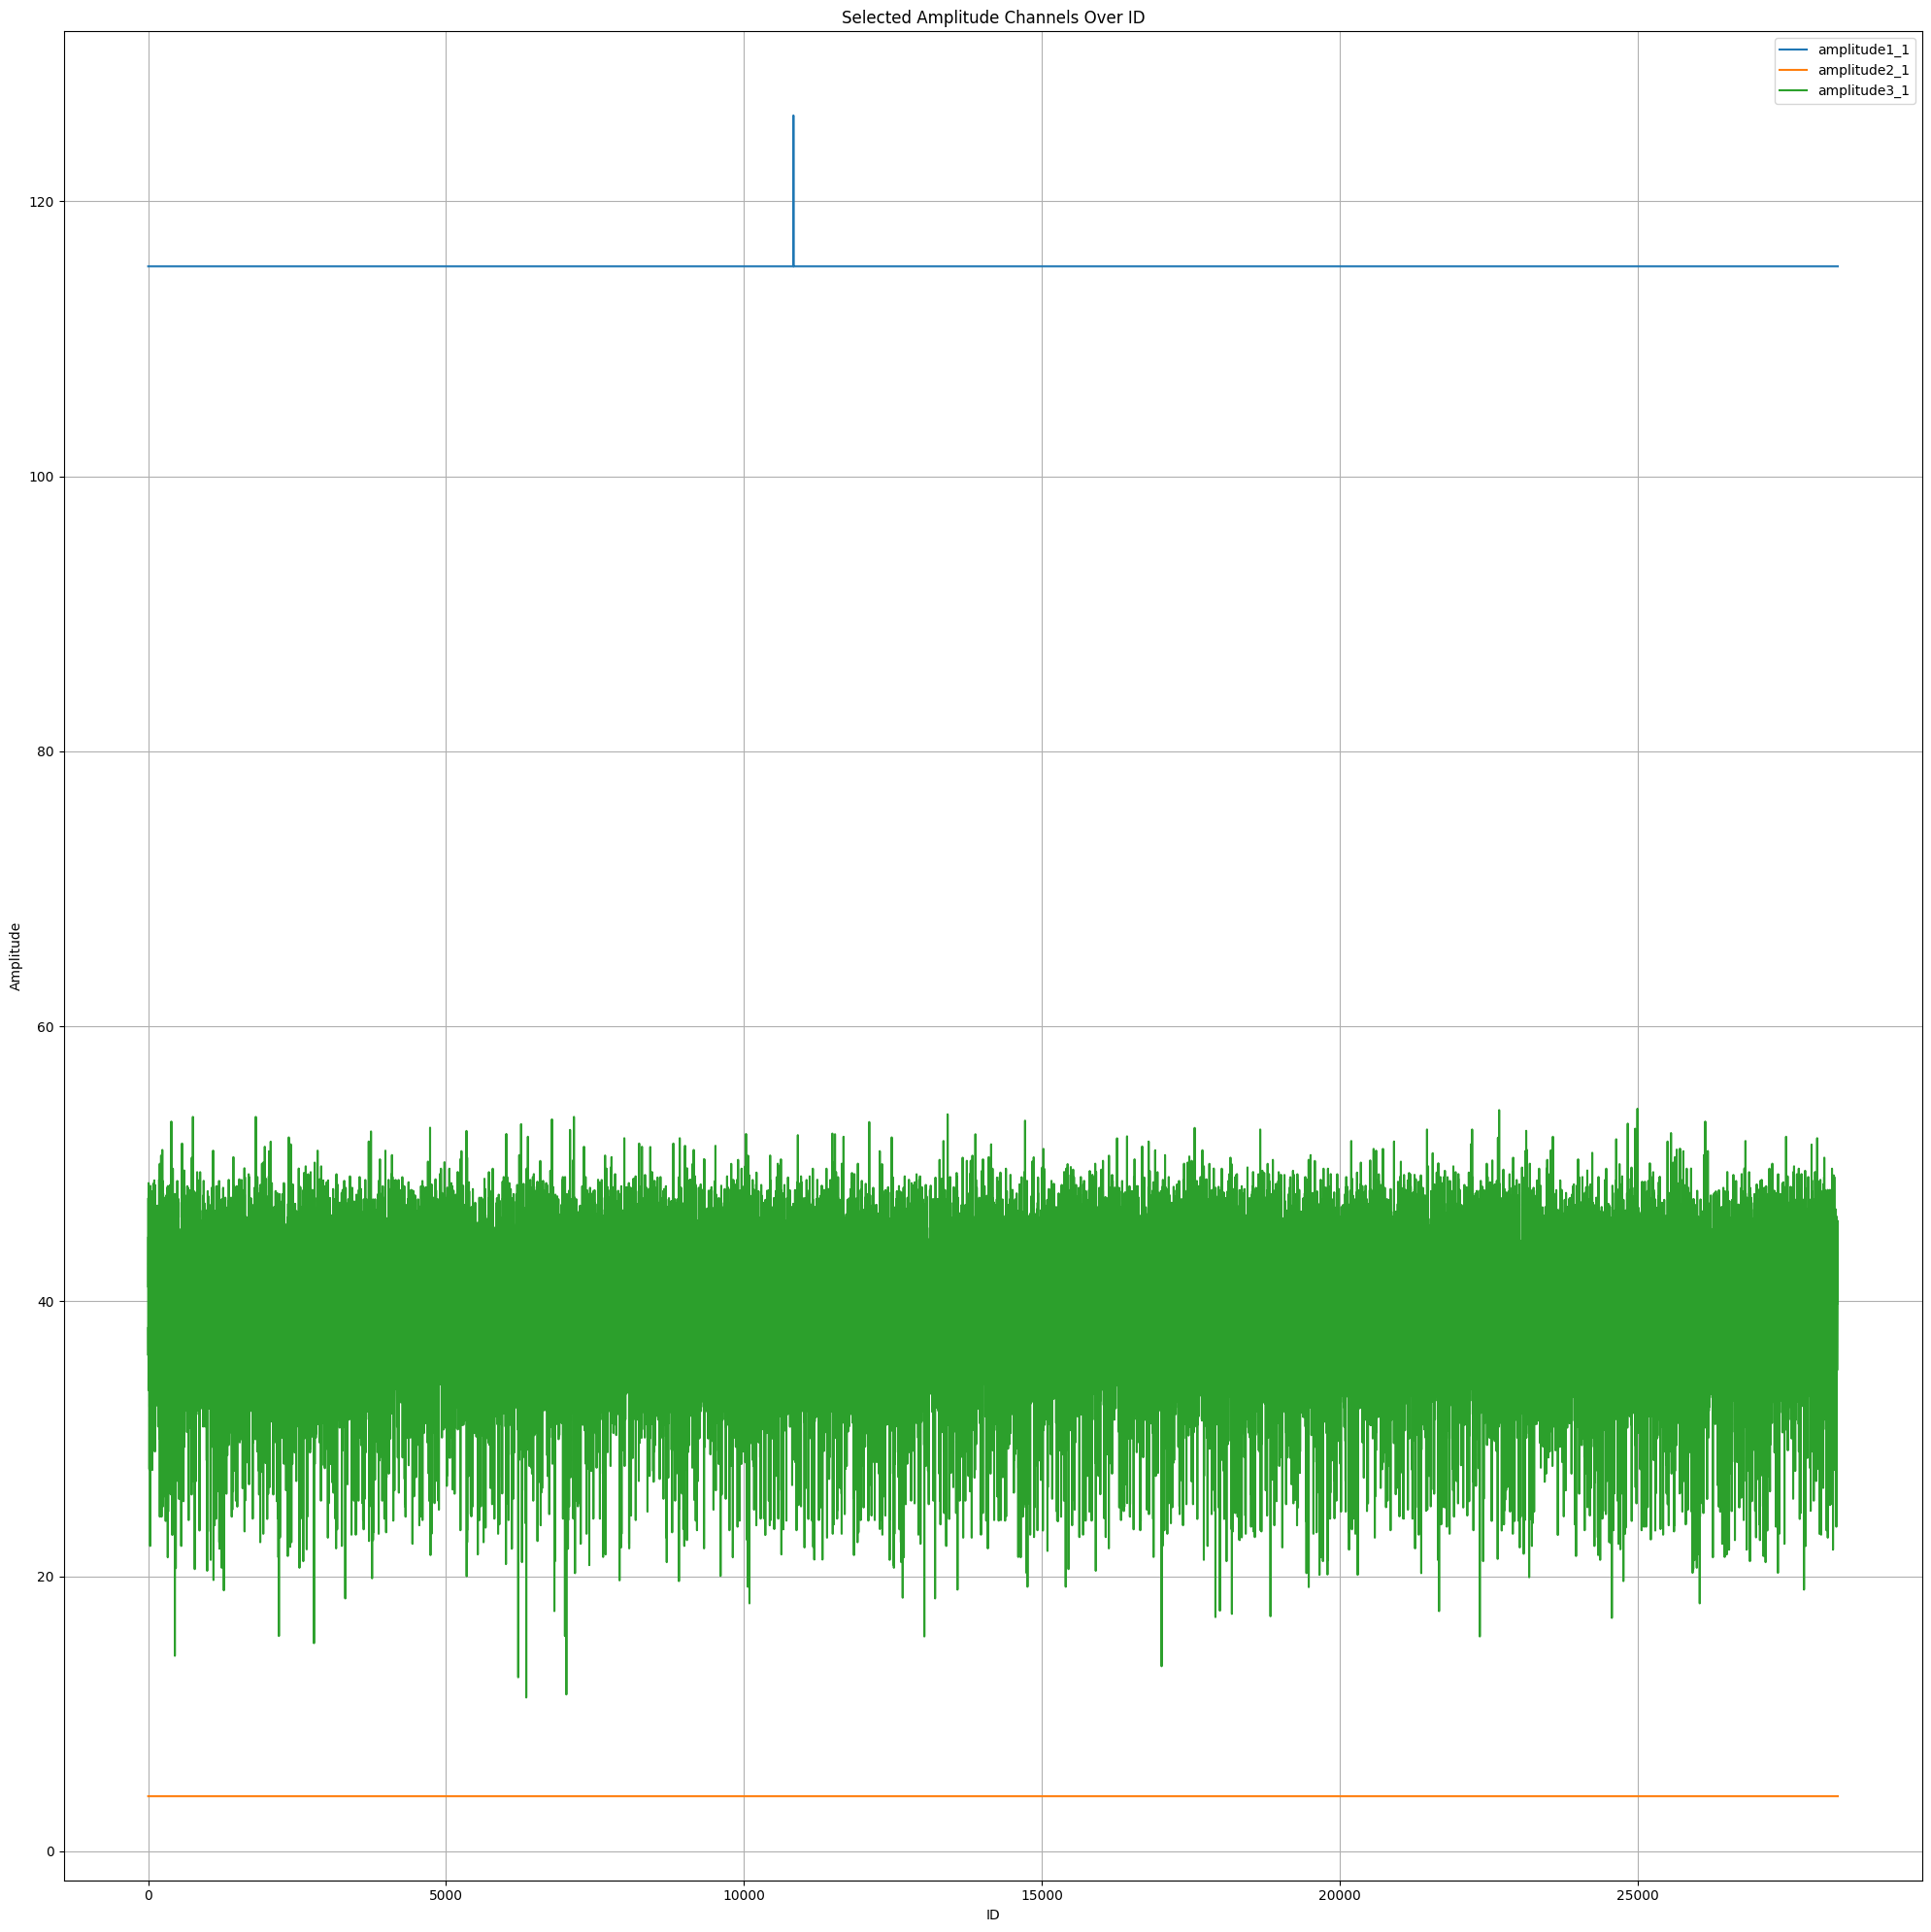

In [31]:
# Plot the selected amplitude channels against the ID
plt.figure(figsize=(20, 20))
for channel in selected_channels:
    plt.plot(a_df['id'], a_df[channel], label=channel)


# Set plot title and labels
plt.title('Selected Amplitude Channels Over ID')
plt.xlabel('ID')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.tight_layout()

# Show plot
plt.show()

In [33]:
def hampel_filter(data, window_size=10, n_sigma=3):
    n = len(data)
    filtered_data = np.copy(data)
    k = 1.4826  # Scale factor for Gaussian distribution (approximation for median absolute deviation)

    for i in range(window_size, n - window_size):
        window = data[i - window_size:i + window_size + 1]
        median = np.median(window)
        mad = np.median(np.abs(window - median))  # Median Absolute Deviation
        threshold = n_sigma * k * mad
        if np.abs(data[i] - median) > threshold:
            filtered_data[i] = median

    return filtered_data

In [34]:
filtered_amplitude_time = ['time'] + [col for col in a_df.columns if 'amplitude' in col]
amplitude_columns = [col for col in a_df.columns if 'amplitude' in col]
for column in amplitude_columns:
    a_df[column] = hampel_filter(a_df[column])

In [35]:
a_df.head()

,time,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,amplitude9_1,...,amplitude57_2,amplitude58_2,amplitude59_2,amplitude60_2,amplitude61_2,amplitude62_2,amplitude63_2,amplitude64_2,activity,id
0,16:23:15,115.277925,4,38.052595,34.000000,30.000000,25.000000,20.024984,16.492423,14.764823,...,-1.849096,-1.661456,-1.487655,-1.387686,-1.341564,-1.332960,-1.357858,-1.368475,1,0
1,18:28:33,115.277925,4,36.069378,36.769553,36.796739,34.713110,32.015621,27.018512,22.022716,...,-2.677945,-2.582993,-2.403778,-2.111216,-1.570796,-1.071450,-0.862170,-0.755104,0,1
2,16:52:57,115.277925,4,47.507894,42.720019,36.055513,29.681644,22.825424,17.720045,14.035669,...,-2.521343,-2.303611,-2.140110,-2.021458,-1.941688,-1.921524,-1.932000,-1.954966,3,2
3,17:46:05,115.277925,4,41.012193,37.013511,30.016662,24.020824,17.029386,11.704700,9.433981,...,-2.273053,-1.892547,-1.661456,-1.496857,-1.415800,-1.410034,-1.401695,-1.416478,1,3
4,17:19:48,115.277925,4,44.687806,39.824616,32.802439,25.000000,17.029386,9.433981,6.324555,...,-1.633215,-1.199905,-0.982794,-0.855053,-0.785398,-0.785398,-0.785398,-0.771315,2,4


In [36]:
# Select the columns representing amplitude channels
#selected_channels = ['amplitude1', 'amplitude2', 'amplitude3', 'amplitude4', 'amplitude5', 'amplitude6']
selected_channels= [f'amplitude{i}_1' for i in range(1, 4)]

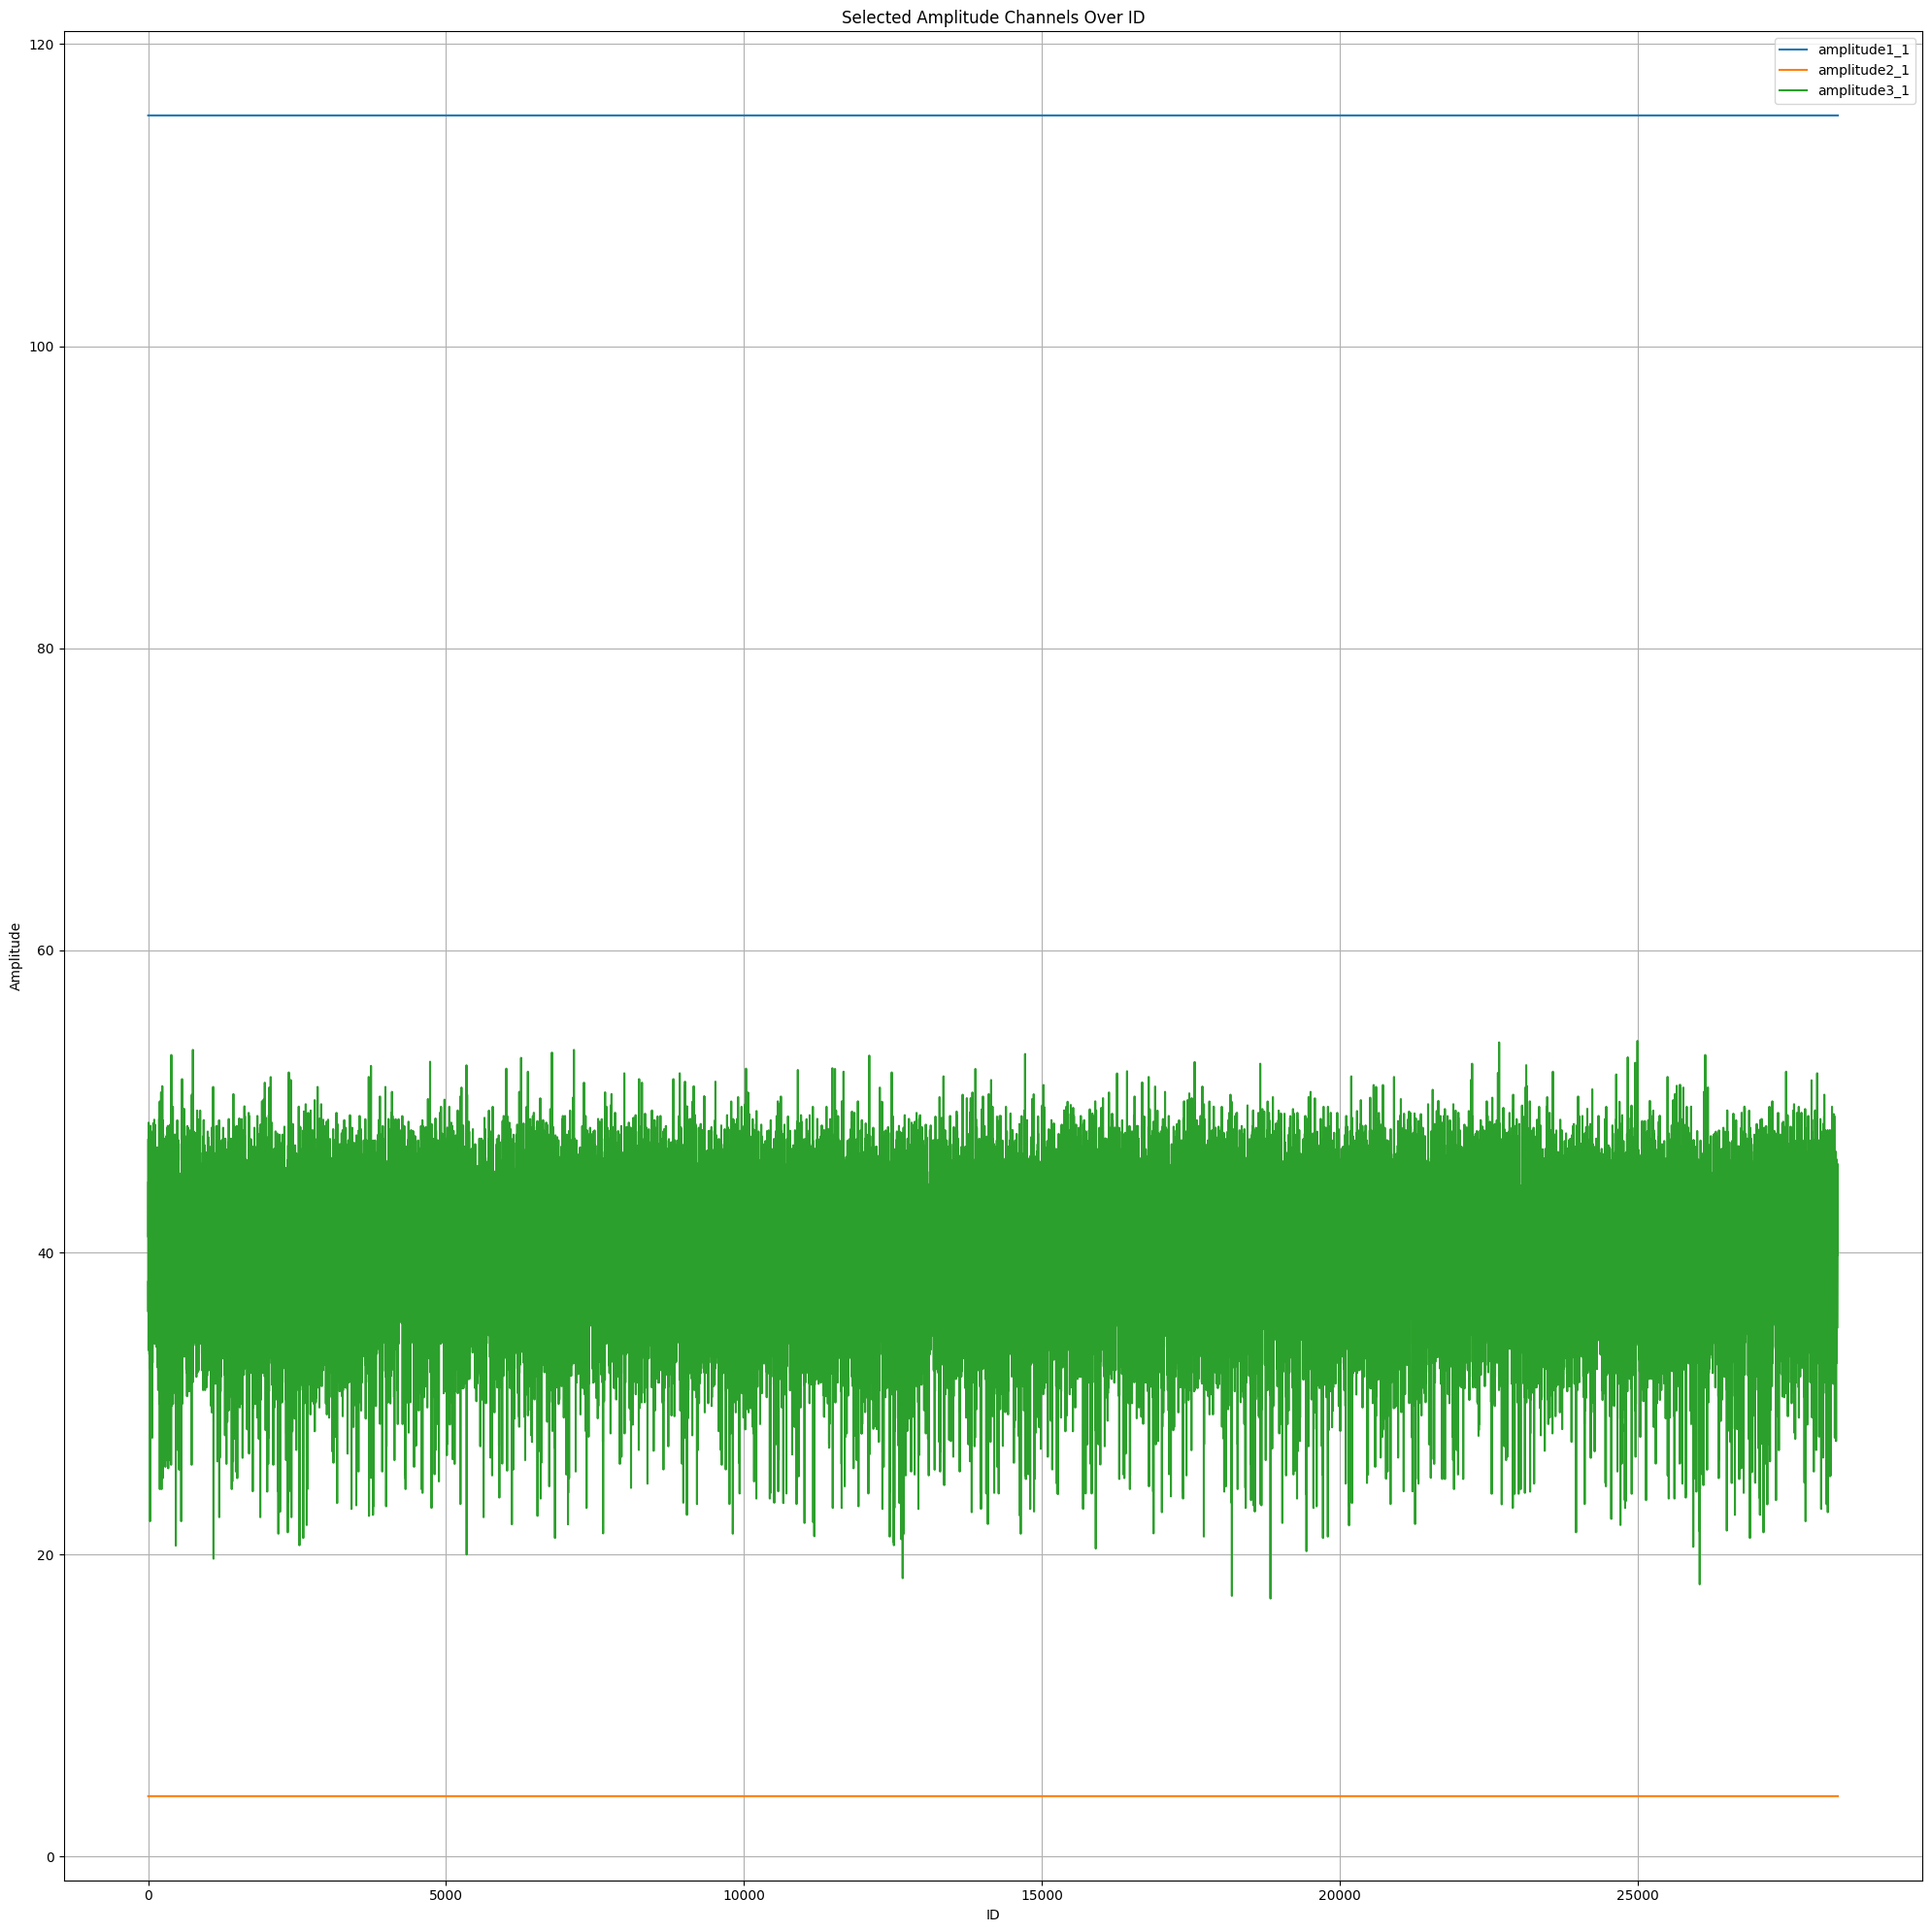

In [37]:
# Plot the selected amplitude channels against the ID
plt.figure(figsize=(20, 20))
for channel in selected_channels:
    plt.plot(a_df['id'], a_df[channel], label=channel)


# Set plot title and labels
plt.title('Selected Amplitude Channels Over ID')
plt.xlabel('ID')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.tight_layout()

# Show plot
plt.show()

In [38]:
amplitude_columns = [col for col in a_df.columns if 'amplitude' in col]
# phase_columns = [col for col in a_df_shuffled.columns if 'phase' in col]

# Replace 'activity_column' with the name of your activity label column
activity_column = 'activity'

In [39]:
# Replace 'sampling_rate' with the sampling rate of your data
sampling_rate = 100  # Assuming a sampling rate of 100 Hz

# Define the cutoff frequency for the filter
cutoff_freq = 10  # Adjust as needed

# Define the order of the filter
filter_order = 4  # Adjust as needed

In [40]:
# Function to design and apply the low-pass filter
def apply_low_pass_filter(data, cutoff_freq, fs, order=4):
    nyquist_freq = 0.5 * fs
    normal_cutoff = cutoff_freq / nyquist_freq
    # Design the filter
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    # Apply the filter to each amplitude column
    filtered_data = filtfilt(b, a, data, axis=0)
    return filtered_data

In [41]:
# Apply the low-pass filter to the amplitude columns
filtered_amplitudes = apply_low_pass_filter(a_df[amplitude_columns].values, cutoff_freq / sampling_rate, 1)

# Update the original DataFrame with the filtered amplitude values
a_df[amplitude_columns] = filtered_amplitudes

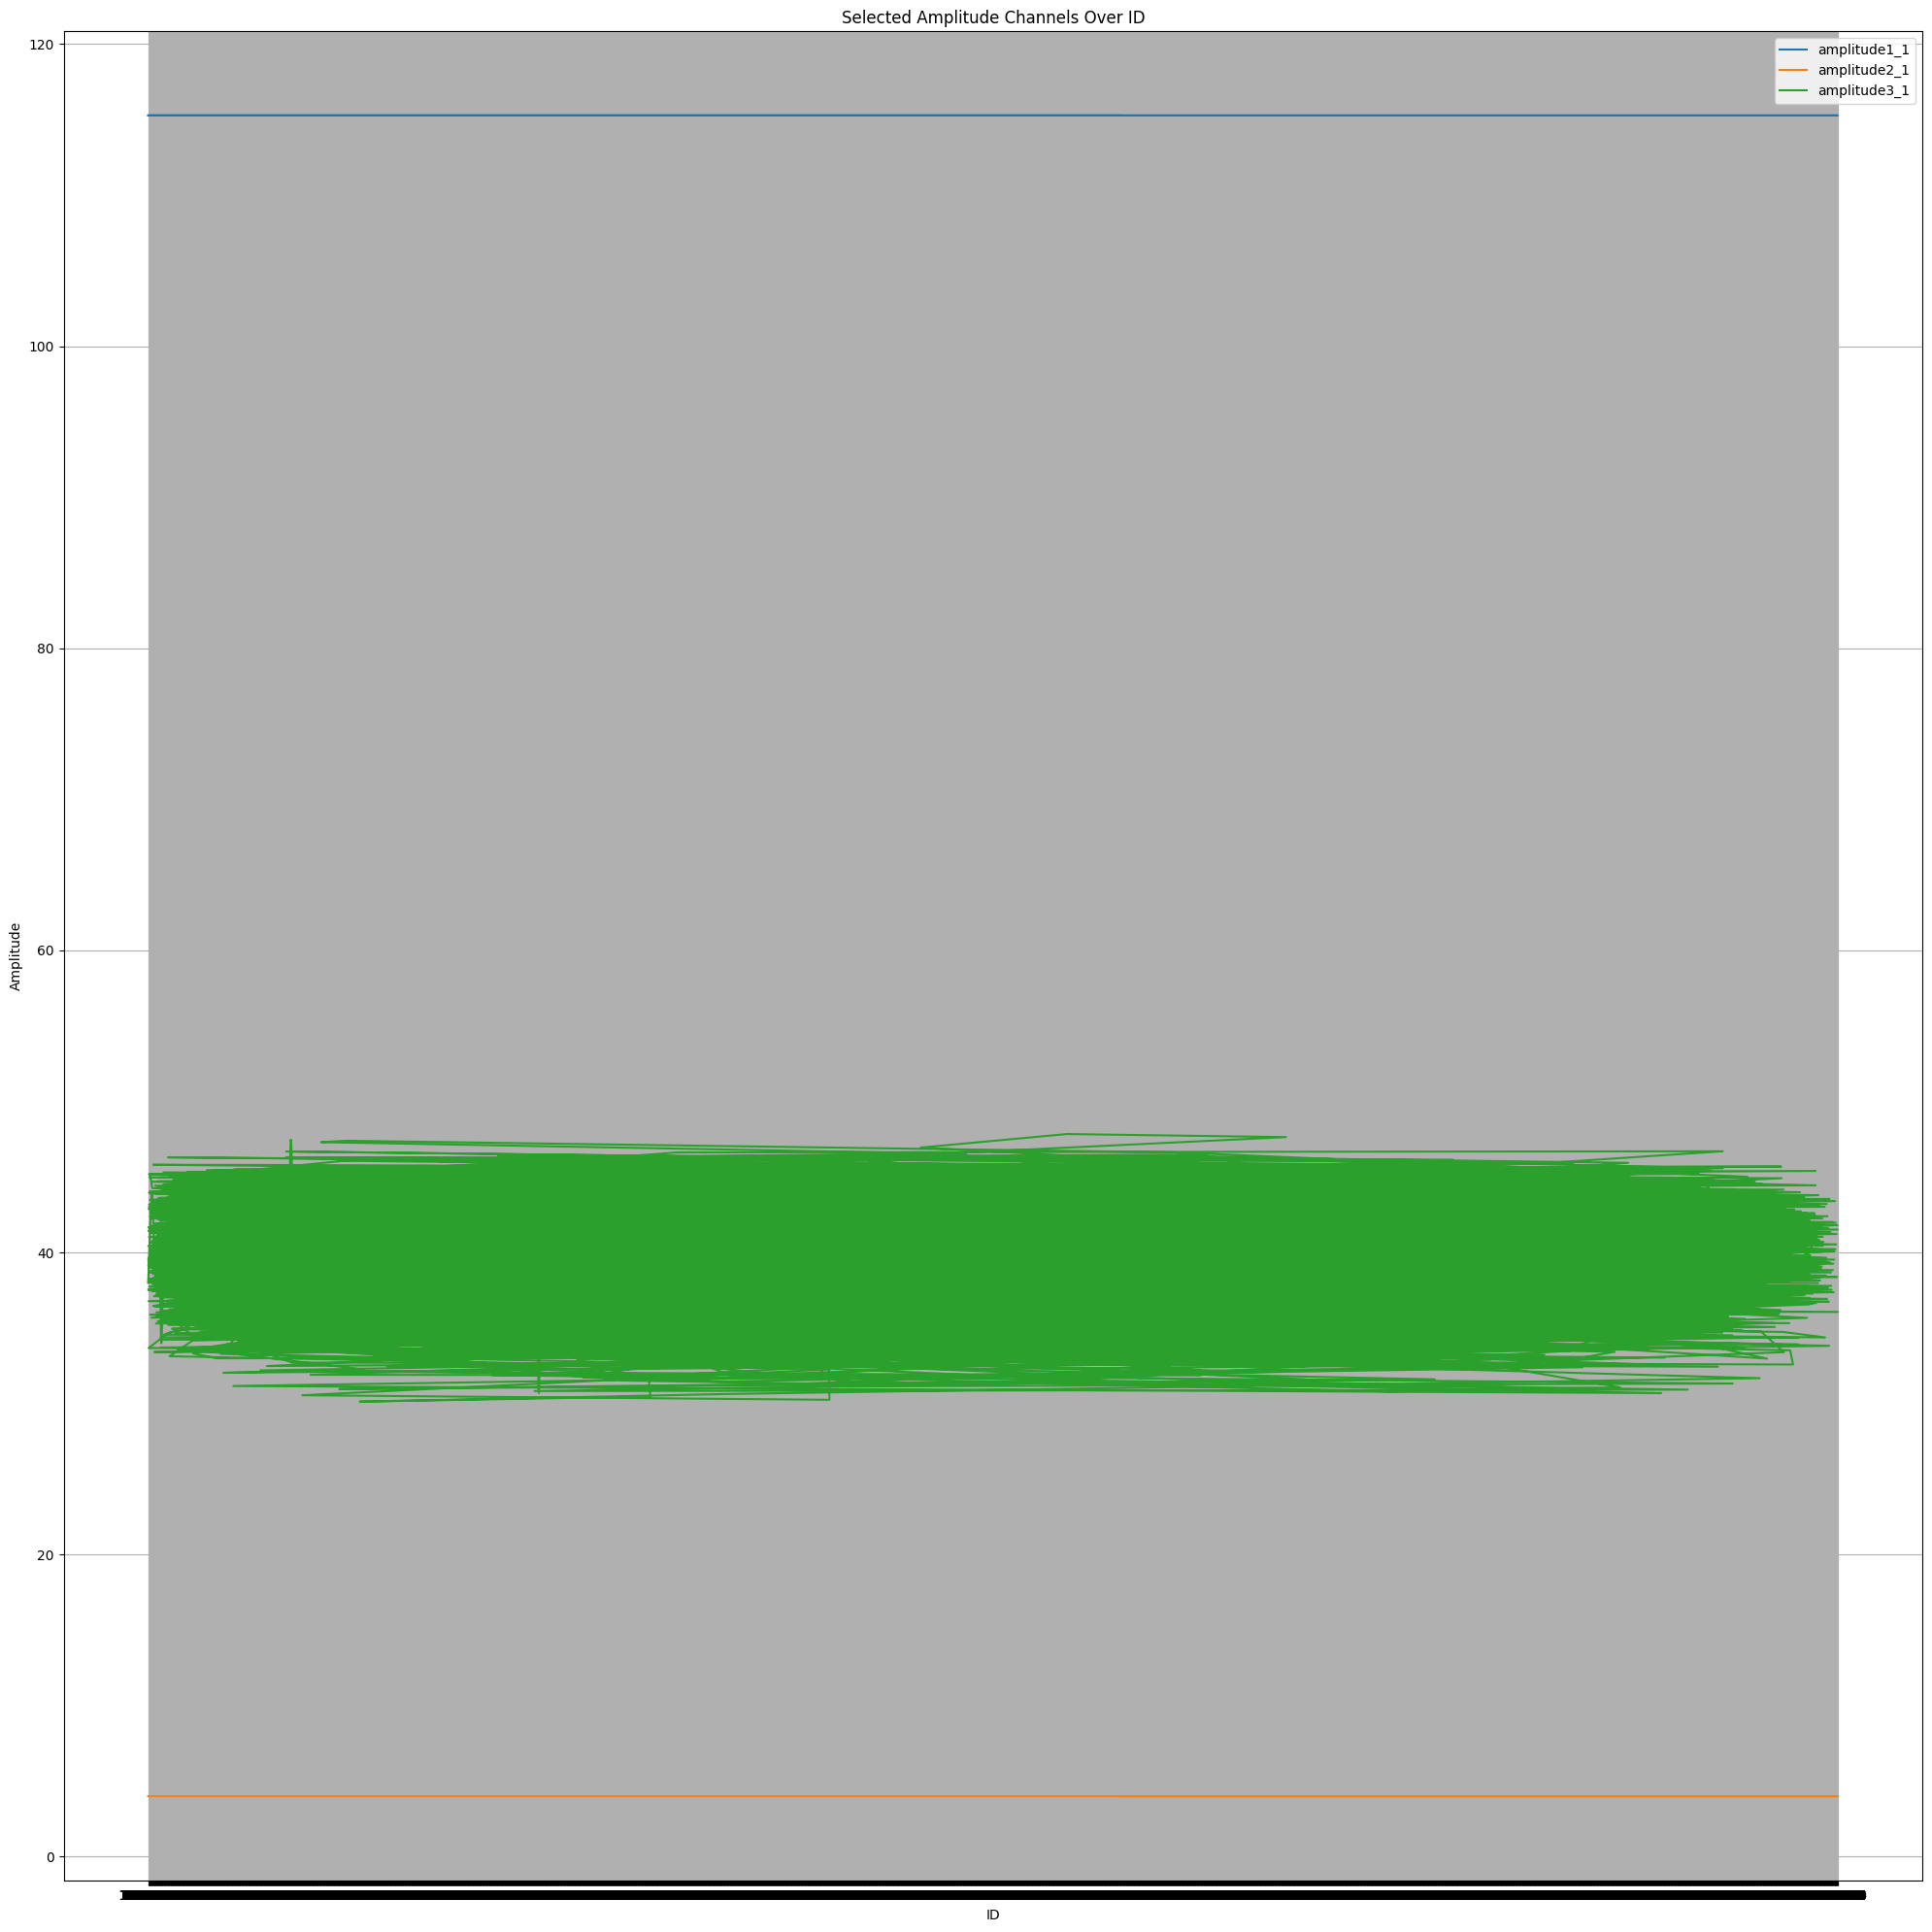

In [42]:
# Plot the selected amplitude channels against the ID
plt.figure(figsize=(20, 20))
for channel in selected_channels:
    plt.plot(a_df['time'], a_df[channel], label=channel)


# Set plot title and labels
plt.title('Selected Amplitude Channels Over ID')
plt.xlabel('ID')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.tight_layout()

# Show plot
plt.show()

In [43]:
# Separate features (X) and labels (y)
# X = a_df_shuffled.drop(columns=['activity','id'])  # Assuming 'label' is the column containing your labels
X = a_df.drop(columns=['activity', 'id', 'time'])
y = a_df['activity']

In [44]:
X

,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,amplitude9_1,amplitude10_1,...,amplitude55_2,amplitude56_2,amplitude57_2,amplitude58_2,amplitude59_2,amplitude60_2,amplitude61_2,amplitude62_2,amplitude63_2,amplitude64_2
0,115.277925,4.0,37.983070,33.923833,29.903771,24.885569,19.902130,16.365476,14.663727,15.496138,...,-2.082754,-1.952944,-1.829405,-1.682567,-1.509086,-1.410527,-1.368569,-1.353321,-1.379831,-1.390928
1,115.277925,4.0,38.894675,34.710239,29.813098,24.408480,18.850182,15.289316,12.949893,14.353680,...,-2.244464,-2.081783,-1.893538,-1.591021,-1.411981,-1.305341,-1.252519,-1.254309,-1.269448,-1.277877
2,115.277925,4.0,39.715699,35.510068,29.968821,24.296537,18.280955,14.698945,11.787723,13.548765,...,-2.236903,-2.047386,-1.804452,-1.394511,-1.213752,-1.099699,-1.091912,-1.105975,-1.108971,-1.114651
3,115.277925,4.0,40.400792,36.355445,30.572668,24.833253,18.564961,14.899295,11.569906,13.306743,...,-1.947980,-1.742790,-1.465400,-1.047978,-0.871895,-0.750836,-0.874163,-0.879874,-0.869086,-0.871666
4,115.277925,4.0,41.010845,37.354680,31.807318,26.233808,19.953232,15.972513,12.483764,13.706863,...,-1.373929,-1.168248,-0.883384,-0.585494,-0.420248,-0.289998,-0.615744,-0.576287,-0.548280,-0.546593
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28361,115.277925,4.0,42.010598,42.336606,40.873567,37.714249,33.563359,28.121761,22.164454,16.810235,...,-1.286875,-1.199352,-1.134285,-1.006649,-1.002701,-0.750364,-1.565761,-1.097840,-0.919840,-0.848382
28362,115.277925,4.0,42.137261,42.301367,40.728109,37.505721,33.273589,27.729091,21.806634,16.741458,...,-0.975386,-0.942232,-0.865795,-0.737066,-0.507516,-0.261553,-1.153901,-1.230901,-1.059133,-0.988807
28363,115.277925,4.0,42.455712,42.795286,41.344896,38.324630,34.156507,28.669095,22.714676,17.614351,...,-0.359444,-0.364239,-0.289130,-0.174913,0.136261,0.406871,-0.221568,-1.589161,-1.409489,-1.337668
28364,115.277925,4.0,42.961591,43.836883,42.754186,40.213056,36.265146,30.994413,24.918646,19.421851,...,0.508661,0.484137,0.543375,0.626854,0.891855,1.207617,1.160909,-2.178924,-1.976507,-1.900304


In [45]:
# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [46]:
# Perform PCA
pca = PCA(n_components=0.80, svd_solver='full')

In [47]:
pca.fit(X_scaled)

PCA(n_components=0.8, svd_solver='full')

In [48]:
X_pca = pd.DataFrame(pca.transform(X_scaled))

In [49]:
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Cumulative explained variance ratio:", np.cumsum(pca.explained_variance_ratio_))

Explained variance ratio: [0.26476844 0.16132257 0.11633381 0.09169807 0.06283203 0.04023487
 0.03304674 0.02587528 0.01921964]
Cumulative explained variance ratio: [0.26476844 0.426091   0.54242482 0.63412289 0.69695491 0.73718978
 0.77023652 0.7961118  0.81533144]


In [50]:
X_pca.head()

,0,1,2,3,4,5,6,7,8
0,-2.821669,-7.334494,3.019583,-1.895882,9.272527,2.987562,-6.200296,-2.334043,0.669661
1,-5.177056,-8.660836,2.910651,-2.323161,7.264985,3.006780,-3.555530,0.827979,-0.041309
2,-6.770549,-9.315936,2.441436,-2.646667,5.030670,3.049651,-1.447717,3.428422,-0.661842
3,-7.041869,-8.855011,1.448773,-2.823278,2.494547,3.096138,-0.190260,5.041760,-1.112444
4,-5.680633,-7.251607,0.004790,-2.937200,-0.178926,3.065591,0.227272,5.476485,-1.345546


In [51]:
X_pca

,0,1,2,3,4,5,6,7,8
0,-2.821669,-7.334494,3.019583,-1.895882,9.272527,2.987562,-6.200296,-2.334043,0.669661
1,-5.177056,-8.660836,2.910651,-2.323161,7.264985,3.006780,-3.555530,0.827979,-0.041309
2,-6.770549,-9.315936,2.441436,-2.646667,5.030670,3.049651,-1.447717,3.428422,-0.661842
3,-7.041869,-8.855011,1.448773,-2.823278,2.494547,3.096138,-0.190260,5.041760,-1.112444
4,-5.680633,-7.251607,0.004790,-2.937200,-0.178926,3.065591,0.227272,5.476485,-1.345546
...,...,...,...,...,...,...,...,...,...
28361,12.465041,-8.034406,5.070957,-0.929513,-0.620337,-0.668059,2.687723,-0.959805,-1.888500
28362,11.926272,-6.213427,4.943175,-1.035293,-0.942553,-0.710090,1.044504,-1.393601,-2.173866
28363,12.880471,-2.580949,5.423733,-1.111101,-1.255459,-0.532189,-1.030879,-1.225918,-2.588884
28364,15.388146,2.644792,6.646823,-1.163292,-1.495057,-0.133790,-3.359023,-0.465357,-3.108036


Continous Wavelet Transform

In [52]:
import pywt

In [53]:
wav = pywt.ContinuousWavelet('cmor1.5-1.0')

In [54]:
# Scale range for wavelet transform
scales = np.arange(1, 128)

In [55]:
def calculate_wavelet_variance(data, wavelet_name):
    variances = []

    for signal in data:  # Iterate over each row (signal)
        # Apply Continuous Wavelet Transform
        coeffs, freqs = pywt.cwt(signal, np.arange(1, 128), wavelet_name, method='conv')

        # Calculate Wavelet Coefficient Power
        coef_power = np.abs(coeffs) ** 2

            # Integrate to Calculate Variance
        variance = np.trapz(coef_power, axis=1)
        variances.append(variance)

    return np.array(variances)

In [56]:
wavelet_variance = calculate_wavelet_variance(np.array(X_pca),wav)

In [57]:
pd.DataFrame(wavelet_variance)

,0,1,2,3,4,5,6,7,8,9,...,117,118,119,120,121,122,123,124,125,126
0,1.420942,24.172400,37.445791,33.030512,81.792886,98.191407,83.273586,61.521242,42.155205,29.038273,...,2.696358,2.719209,2.742059,2.764910,2.787760,2.810611,2.833461,2.856312,2.879162,2.902013
1,1.026306,20.813453,33.774098,12.380730,47.783637,67.468492,67.044649,58.928946,49.067690,40.807900,...,2.817889,2.841769,2.865650,2.889530,2.913410,2.937291,2.961171,2.985052,3.008932,3.032812
2,0.849213,16.133723,30.727222,10.703906,28.190735,41.767122,53.103730,59.646250,60.839827,58.348446,...,2.864049,2.888321,2.912592,2.936864,2.961136,2.985407,3.009679,3.033951,3.058222,3.082494
3,0.687576,10.775662,24.723263,13.815837,15.616689,20.949161,37.978698,53.675846,62.418307,64.270644,...,2.665875,2.688467,2.711059,2.733651,2.756243,2.778835,2.801428,2.824020,2.846612,2.869204
4,0.462443,7.631766,15.401338,11.268999,5.980957,7.939573,23.936702,39.663534,49.178674,52.153510,...,2.365248,2.385292,2.405337,2.425381,2.445426,2.465470,2.485515,2.505559,2.525604,2.545648
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28361,0.553689,69.537087,54.781991,15.314669,9.982000,15.816967,11.212228,6.713915,5.323528,6.002598,...,7.406814,7.469584,7.532354,7.595123,7.657893,7.720662,7.783432,7.846202,7.908971,7.971741
28362,0.427941,54.479687,40.453137,9.626910,9.476146,11.987401,8.074656,7.036496,9.164104,12.136211,...,6.076650,6.128147,6.179644,6.231141,6.282638,6.334135,6.385632,6.437129,6.488626,6.540123
28363,0.437964,41.187295,24.880283,6.213028,13.752125,15.379469,15.286802,20.800740,28.635581,34.845892,...,6.250001,6.302967,6.355933,6.408899,6.461866,6.514832,6.567798,6.620764,6.673730,6.726696
28364,0.850384,33.722615,14.261628,12.906564,30.359618,37.074377,47.248020,64.520700,81.071502,91.267505,...,9.483418,9.563786,9.644154,9.724522,9.804890,9.885258,9.965625,10.045993,10.126361,10.206729


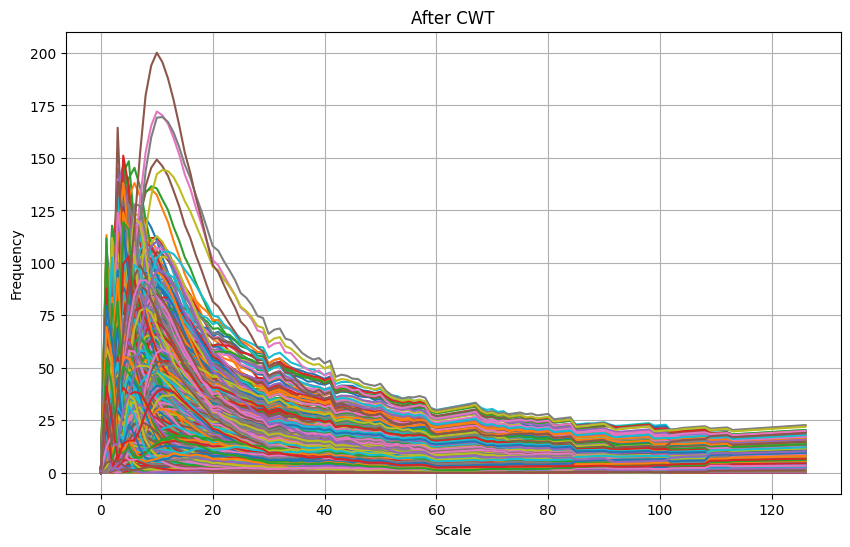

In [58]:
plt.figure(figsize=(10, 6))
for row in wavelet_variance:
    plt.plot(row)
plt.xlabel('Scale')
plt.ylabel('Frequency')
plt.title('After CWT')
plt.grid(True)
plt.show()

Discrete wavelet variance

In [59]:
# Define the wavelet function
wavelet_name = 'db6'
level = 2

In [556]:
def calculate_dwt_variance(dataset, wavelet='db6'):
    variances = []
    
    # Ensure dataset is 2D
    if len(dataset.shape) == 1:
        dataset = np.expand_dims(dataset, axis=0)
    
    # Iterate over each row (signal) in the dataset
    for row in dataset:
        # Perform Discrete Wavelet Transform (DWT)
        coeffs = pywt.wavedec(row, wavelet)
        
        # Calculate variance of DWT coefficients
        variance = np.var(coeffs)
        
        # Append variance to the list
        variances.append(variance)
    
    return variances

Accuracy before PCA

In [131]:
X_train, X_val, y_train, y_val = train_test_split(pd.DataFrame(X_scaled), y, test_size=0.2, random_state=42)

In [132]:
from sklearn import svm

classifier = svm.SVC(kernel='linear')  

In [133]:
classifier.fit(X_train, y_train)

KeyboardInterrupt: 

In [ ]:
y_val_pred = classifier.predict(X_val)

In [ ]:
# Model Evaluation (Optional)
# Evaluate the trained model's performance on the validation set
accuracy = metrics.accuracy_score(y_val_pred, y_val)
print("Validation Accuracy before PCA:", accuracy)

Accuracy after CWT

In [60]:
X_train, X_val, y_train, y_val = train_test_split(pd.DataFrame(wavelet_variance), y, test_size=0.2, random_state=42)

Accuracy after PCA

In [703]:
# Split the dataset into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X_pca, y, test_size=0.2, random_state=42)

In [61]:
X_train.head()

,0,1,2,3,4,5,6,7,8,9,...,117,118,119,120,121,122,123,124,125,126
6646,0.182729,34.082876,18.221692,1.120033,2.990288,4.569125,6.001572,7.114931,7.816779,8.279577,...,3.688431,3.719689,3.750947,3.782205,3.813463,3.844721,3.875979,3.907237,3.938495,3.969752
12058,0.483572,32.628950,38.303243,23.748395,18.066089,11.430585,7.097061,4.759965,3.482897,2.841099,...,3.253497,3.281069,3.308641,3.336213,3.363785,3.391357,3.418929,3.446501,3.474073,3.501645
23619,0.637260,9.402588,7.322111,20.014658,33.100247,30.009968,29.433141,33.555379,37.915430,40.230562,...,2.099377,2.117169,2.134960,2.152751,2.170543,2.188334,2.206125,2.223917,2.241708,2.259499
19828,0.359601,34.066872,28.038281,7.977736,9.894929,16.399656,14.275931,9.395220,5.189839,2.676327,...,4.192215,4.227742,4.263269,4.298797,4.334324,4.369851,4.405378,4.440906,4.476433,4.511960
16047,0.435047,0.307478,7.715340,19.513404,18.834495,17.428453,17.321656,17.412281,17.202740,17.226540,...,2.462041,2.482906,2.503771,2.524636,2.545500,2.566365,2.587230,2.608095,2.628959,2.649824


In [69]:
y_train.head()

6646     0
12058    0
23619    0
19828    0
16047    0
Name: activity, dtype: int64

In [63]:
X_train.isnull().sum()

0      0
1      0
2      0
3      0
4      0
      ..
122    0
123    0
124    0
125    0
126    0
Length: 127, dtype: int64

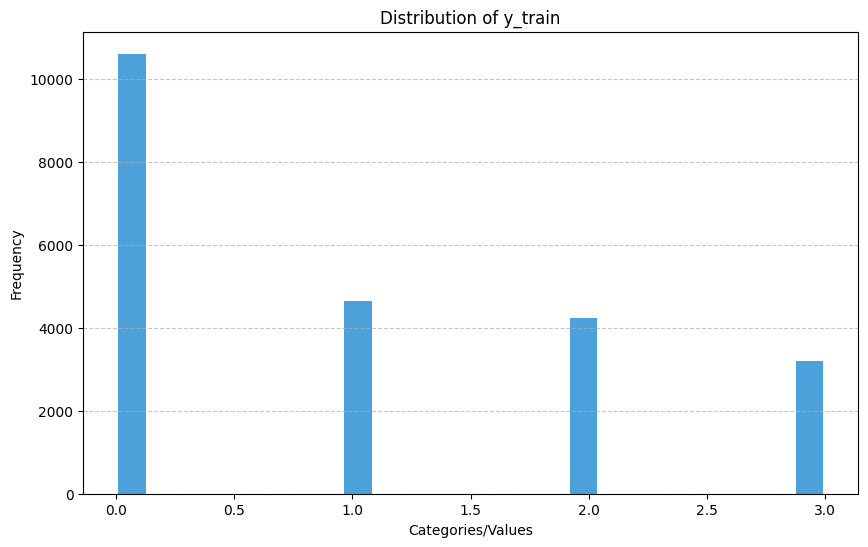

In [64]:
# Assuming y_train is your target variable
plt.figure(figsize=(10, 6))
plt.hist(y_train, bins='auto', color='#007acc', alpha=0.7, rwidth=0.85)
plt.title('Distribution of y_train')
plt.xlabel('Categories/Values')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add any additional customization as needed
plt.show()

In [65]:
from sklearn import svm

classifier = svm.SVC(kernel='linear')  


In [66]:
classifier.fit(X_train, y_train)

SVC(kernel='linear')

In [67]:
y_val_pred = classifier.predict(X_val)

In [68]:
print(y_val.shape)

(5674,)


In [70]:
print(y_val_pred.shape)

(5674,)


In [71]:
# Model Evaluation (Optional)
# Evaluate the trained model's performance on the validation set
accuracy = metrics.accuracy_score(y_val_pred, y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.46087416284807897


In [72]:
print('Confusion matrix :', metrics.confusion_matrix(y_val, y_val_pred))

Confusion matrix : [[2615    0    0    0]
 [1136    0    0    0]
 [1123    0    0    0]
 [ 800    0    0    0]]


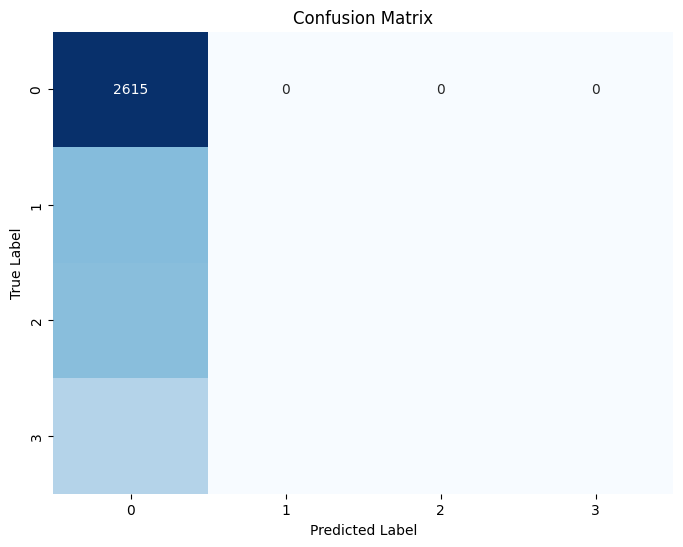

In [73]:
# Generate the confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()